# Evaluation, monitoring and responsible actions

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
metrics=json.loads((ROOT/'outputs/metrics/evaluation.json').read_text())
pd.Series(metrics['test_churn'])

pr_auc            0.596905
roc_auc           0.735012
brier             0.215601
prevalence        0.393064
lift_top_10pct    1.726694
dtype: float64

In [3]:
scores=pd.read_csv(ROOT/'outputs/tableau/customer_scores.csv')
scores.groupby('risk_band').agg(customers=('customer_id','nunique'),mean_risk=('inactivity_probability','mean'),predicted_spending=('predicted_spend_90','sum'))

,customers,mean_risk,predicted_spending
risk_band,,,
High,1298,0.685914,1.567199e+05
Low,773,0.168604,1.226727e+06
Medium,1401,0.461926,4.094223e+05


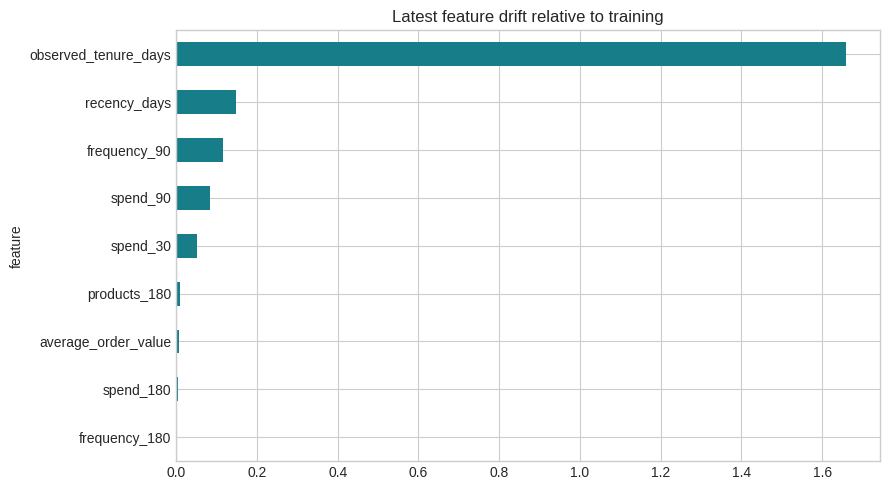

In [4]:
drift=pd.read_csv(ROOT/'outputs/tableau/feature_drift.csv')
drift.sort_values('psi').plot.barh(x='feature',y='psi',figsize=(9,5),legend=False,color='#177e89')
plt.title('Latest feature drift relative to training');plt.tight_layout();plt.show()

In [5]:
scores[['customer_id','inactivity_probability','predicted_spend_90','spend_90','priority_proxy']].head(10)

,customer_id,inactivity_probability,predicted_spend_90,spend_90,priority_proxy
0,16000,0.332691,5874.928500,12393.70,4123.267788
1,12357,0.411912,884.633213,6207.67,2557.010740
2,15195,0.640822,873.133719,3861.00,2474.213852
3,12752,0.510856,908.216108,4366.78,2230.796548
4,12536,0.485596,983.941892,4279.71,2078.210724
5,18251,0.468683,819.280534,4314.72,2022.235178
6,12435,0.471690,824.995577,3850.90,1816.429640
7,12454,0.490806,784.126544,3528.34,1731.729556
8,12753,0.350664,1194.213422,4808.48,1686.161903
9,12409,0.333335,1804.658906,4865.59,1621.869198


## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.